# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170381         # <-- your full roll number
NAME = "Pushkar"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170384   Name: Deeksha   Fingerprint: 94D198E2   Tickets: 16

Ticket_ID                                                                                Ticket_Text
      T01                                            The VPN keeps asking for login. This is urgent.
      T02                                                                My roll no. is 1023-03-021.
      T03                                   Python failed to open on my laptop. It worked yesterday.
      T04 I keep getting logged out of the LMS while uploading the file. I have tried several times!
      T05                           I reinstalled the email on my laptop. I don't know what changed.
      T06                                                  The printer won't print; it isn't jammed.
      T07                                                                The file is 95.5% uploaded.
      T08 I was locked out of the Python after restarting the system. The same problem occurs again.
      T09   

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
results = [process_ticket(text) for text in df["Ticket_Text"]]

rows = []

for ticket_id, result in zip(df["Ticket_ID"], results):
    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": result["sentences"],
        "Tokens": result["tokens"],
        "Punctuation": result["punct"],
        "Stopwords": result["stops"],
        "Unique Tokens": list(dict.fromkeys(result["final"])),
        "Final Tokens": result["final"]
    })

q1_table = pd.DataFrame(rows)

total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": sum(len(r["sentences"]) for r in results),
    "Tokens": sum(len(r["tokens"]) for r in results),
    "Punctuation": sum(len(r["punct"]) for r in results),
    "Stopwords": sum(len(r["stops"]) for r in results),
    "Unique Tokens": len(set(t for r in results for t in r["final"])),
    "Final Tokens": sum(len(r["final"]) for r in results)
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)

display(q1_table)

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,"[The VPN keeps asking for login., This is urgent.]","[the, vpn, keeps, asking, for, login, ., this, is, urgent, .]","[., .]","[the, for, this, is]","[vpn, keeps, asking, login, urgent]","[vpn, keeps, asking, login, urgent]"
1,T02,"[My roll no., is 1023-03-021.]","[my, roll, no, ., is, 1023-03-021, .]","[., .]","[my, no, is]","[roll, 1023-03-021]","[roll, 1023-03-021]"
2,T03,"[Python failed to open on my laptop., It worked yesterday.]","[python, failed, to, open, on, my, laptop, ., it, worked, yesterday, .]","[., .]","[to, on, my, it]","[python, failed, open, laptop, worked, yesterday]","[python, failed, open, laptop, worked, yesterday]"
3,T04,"[I keep getting logged out of the LMS while uploading the file., I have tried several times!]","[i, keep, getting, logged, out, of, the, lms, while, uploading, the, file, ., i, have, tried, several, times, !]","[., !]","[i, out, of, the, while, the, i, have]","[keep, getting, logged, lms, uploading, file, tried, several, times]","[keep, getting, logged, lms, uploading, file, tried, several, times]"
4,T05,"[I reinstalled the email on my laptop., I don't know what changed.]","[i, reinstalled, the, email, on, my, laptop, ., i, do, n't, know, what, changed, .]","[., .]","[i, the, on, my, i, do, what]","[reinstalled, email, laptop, n't, know, changed]","[reinstalled, email, laptop, n't, know, changed]"
5,T06,[The printer won't print; it isn't jammed.],"[the, printer, wo, n't, print, ;, it, is, n't, jammed, .]","[;, .]","[the, it, is]","[printer, wo, n't, print, jammed]","[printer, wo, n't, print, n't, jammed]"
6,T07,[The file is 95.5% uploaded.],"[the, file, is, 95.5, %, uploaded, .]","[%, .]","[the, is]","[file, 95.5, uploaded]","[file, 95.5, uploaded]"
7,T08,"[I was locked out of the Python after restarting the system., The same problem occurs again.]","[i, was, locked, out, of, the, python, after, restarting, the, system, ., the, same, problem, occurs, again, .]","[., .]","[i, was, out, of, the, after, the, the, same, again]","[locked, python, restarting, system, problem, occurs]","[locked, python, restarting, system, problem, occurs]"
8,T09,"[The lms failed to open., I don't know what changed.]","[the, lms, failed, to, open, ., i, do, n't, know, what, changed, .]","[., .]","[the, to, i, do, what]","[lms, failed, open, n't, know, changed]","[lms, failed, open, n't, know, changed]"
9,T10,"[I reinstalled the Wi-Fi since yesterday., I don't know what changed.]","[i, reinstalled, the, wi-fi, since, yesterday, ., i, do, n't, know, what, changed, .]","[., .]","[i, the, i, do, what]","[reinstalled, wi-fi, since, yesterday, n't, know, changed]","[reinstalled, wi-fi, since, yesterday, n't, know, changed]"


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Some final tokens such as n't, 's, and ca are not meaningful standalone English words. They originate from contractions in the original text.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

long_words_pattern = r"\b[A-Za-z]{6,}\b"

numbers_pattern = r"(?<![\w.])\d+(?:\.\d+)+(?![\w.])|(?<![\w.])\d+(?![\w.])"

capitalized_pattern = r"\b[A-Z][a-zA-Z]*\b"

vowel_pattern = r"\b[AEIOUaeiou][a-zA-Z]*\b"

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

url_pattern = r"https?://[^\s]+|www\.[^\s]+"

phone_pattern = (
    r"(?<![\w.])"
    r"(?:\+91[\s-]?\d{5}[\s-]?\d{5}"
    r"|\d{4}[- ]\d{3}[- ]\d{4}"
    r"|\d{10})"
    r"(?![\w.])"
)

all_text = " ".join(df["Ticket_Text"].tolist())

long_words = re.findall(long_words_pattern, all_text)
numbers = re.findall(numbers_pattern, all_text)
capitalized_words = re.findall(capitalized_pattern, all_text)
vowel_words = re.findall(vowel_pattern, all_text)

print("Words longer than 5 letters:")
print(long_words)

print("\nNumbers:")
print(numbers)

print("\nCapitalized words:")
print(capitalized_words)

print("\nWords starting with a vowel:")
print(vowel_words)

def anonymize_text(text):
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text


print("\nAnonymized TEST_LINES:")

for line in TEST_LINES:
    print(anonymize_text(line))

print("\nAnonymized tickets:")

for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    print(ticket_id, ":", anonymize_text(text))

Words longer than 5 letters:
['asking', 'urgent', 'Python', 'failed', 'laptop', 'worked', 'yesterday', 'getting', 'logged', 'uploading', 'several', 'reinstalled', 'laptop', 'changed', 'printer', 'jammed', 'uploaded', 'locked', 'Python', 'restarting', 'system', 'problem', 'occurs', 'failed', 'changed', 'reinstalled', 'yesterday', 'changed', 'Password', 'asking', 'before', 'assignment', 'deadline', 'Laptop', 'disconnecting', 'yesterday', 'Please', 'crashes', 'opening', 'during', 'several', 'response', 'Projector', 'working', 'restarting', 'system', 'another', 'solution', 'disconnecting', 'yesterday', 'Please']

Numbers:
['1023', '03', '95.5']

Capitalized words:
['The', 'VPN', 'This', 'My', 'Python', 'It', 'I', 'LMS', 'I', 'I', 'I', 'The', 'The', 'I', 'Python', 'The', 'The', 'I', 'I', 'Wi', 'Fi', 'I', 'Password', 'Can', 'Laptop', 'Please', 'VPN', 'I', 'I', 'Projector', 'Is', 'LMS', 'Please']

Words starting with a vowel:
['asking', 'is', 'urgent', 'is', 'open', 'on', 'It', 'I', 'out', 'o

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Some capitalized words are not proper nouns or technical names. They are capitalized simply because they appear at the beginning of a sentence.

For example, words such as The, I, It, and Please may be capitalized because of their sentence position.

The exact number can be determined by comparing the extracted capitalized words with their positions in the original tickets. Capitalized technical terms such as Python, MATLAB, LMS, and VPN should not automatically be classified as sentence-initial capitalization.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Q3. Custom tokenizer

from nltk.tokenize import RegexpTokenizer, word_tokenize

# One regular expression pattern
pattern = (
    r"https?://[^\s]+|www\.[^\s]+|"                    # URLs
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|" # Emails
    r"\+91[\s-]?\d{5}[\s-]?\d{5}|"                     # Indian phone numbers
    r"\d{4}[- ]\d{3}[- ]\d{4}|"                        # Landline-style numbers
    r"\d{10}|"                                         # 10-digit numbers
    r"\d+(?:\.\d+)+|"                                  # Decimals and versions
    r"[A-Za-z]+(?:-[A-Za-z]+)+|"                      # Hyphenated words
    r"[A-Za-z]+(?:['’][A-Za-z]+)+|"                    # Contractions
    r"[A-Za-z]+|"                                      # Normal words
    r"\d+|"                                            # Integers
    r"[^\w\s]"                                         # Remaining punctuation
)

my_tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return my_tokenizer.tokenize(text)


# Test on TEST_LINES

print("CUSTOM TOKENIZATION OF TEST_LINES")

for i, line in enumerate(TEST_LINES, 1):
    print(f"\nTest Line {i}:")
    print("Original:", line)
    print("Custom:", my_tokenize(line))
    print("NLTK:", word_tokenize(line))


# Apply both tokenizers to generated tickets

comparison = []

different_tickets = []

for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):

    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    is_different = custom_tokens != nltk_tokens

    comparison.append({
        "Ticket_ID": ticket_id,
        "Custom Tokens": custom_tokens,
        "NLTK Tokens": nltk_tokens,
        "Different": is_different
    })

    if is_different:
        different_tickets.append(ticket_id)


comparison_df = pd.DataFrame(comparison)

display(comparison_df)

print("\nTotal tickets:", len(df))
print("Tickets tokenized differently:", len(different_tickets))
print("Different ticket IDs:", different_tickets)

CUSTOM TOKENIZATION OF TEST_LINES

Test Line 1:
Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Test Line 2:
Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
NLTK: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Test Line 3:
Original: The state-of-the-ar

,Ticket_ID,Custom Tokens,NLTK Tokens,Different
0,T01,"[The, VPN, keeps, asking, for, login, ., This, is, urgent, .]","[The, VPN, keeps, asking, for, login, ., This, is, urgent, .]",False
1,T02,"[My, roll, no, ., is, 1023, -, 03, -, 021, .]","[My, roll, no, ., is, 1023-03-021, .]",True
2,T03,"[Python, failed, to, open, on, my, laptop, ., It, worked, yesterday, .]","[Python, failed, to, open, on, my, laptop, ., It, worked, yesterday, .]",False
3,T04,"[I, keep, getting, logged, out, of, the, LMS, while, uploading, the, file, ., I, have, tried, several, times, !]","[I, keep, getting, logged, out, of, the, LMS, while, uploading, the, file, ., I, have, tried, several, times, !]",False
4,T05,"[I, reinstalled, the, email, on, my, laptop, ., I, don't, know, what, changed, .]","[I, reinstalled, the, email, on, my, laptop, ., I, do, n't, know, what, changed, .]",True
5,T06,"[The, printer, won't, print, ;, it, isn't, jammed, .]","[The, printer, wo, n't, print, ;, it, is, n't, jammed, .]",True
6,T07,"[The, file, is, 95.5, %, uploaded, .]","[The, file, is, 95.5, %, uploaded, .]",False
7,T08,"[I, was, locked, out, of, the, Python, after, restarting, the, system, ., The, same, problem, occurs, again, .]","[I, was, locked, out, of, the, Python, after, restarting, the, system, ., The, same, problem, occurs, again, .]",False
8,T09,"[The, lms, failed, to, open, ., I, don't, know, what, changed, .]","[The, lms, failed, to, open, ., I, do, n't, know, what, changed, .]",True
9,T10,"[I, reinstalled, the, Wi-Fi, since, yesterday, ., I, don't, know, what, changed, .]","[I, reinstalled, the, Wi-Fi, since, yesterday, ., I, do, n't, know, what, changed, .]",True



Total tickets: 16
Tickets tokenized differently: 6
Different ticket IDs: ['T02', 'T05', 'T06', 'T09', 'T10', 'T14']


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*  The custom tokenizer and NLTK's word_tokenize() use different tokenization rules.

The custom tokenizer keeps contractions, hyphenated words, decimal numbers, version numbers, email addresses, URLs and phone numbers together as single tokens.

On the other hand, word_tokenize() generally splits contractions and hyphenated expressions into multiple tokens.

Therefore, the number of differently tokenized tickets is calculated by comparing both token lists for every ticket. The exact count is printed by the program.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Q4. Stemming and lemmatization

from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

porter = PorterStemmer()
lancaster = LancasterStemmer()

# Custom suffix-based stemmer
regex_stemmer = RegexpStemmer(
    r"(ing|ed|ly|s)$",
    min=4
)

lemmatizer = WordNetLemmatizer()


# Collect unique final tokens from all tickets
unique_final_tokens = sorted(
    set(token for result in results for token in result["final"])
)


# Convert POS tags into WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"       # Adjective
    elif tag.startswith("V"):
        return "v"       # Verb
    elif tag.startswith("N"):
        return "n"       # Noun
    elif tag.startswith("R"):
        return "r"       # Adverb
    else:
        return "n"


# POS tagging
tagged_words = pos_tag(unique_final_tokens)

comparison_results = []

for word, tag in tagged_words:

    pos = get_wordnet_pos(tag)

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regex_result = regex_stemmer.stem(word)
    lemma_result = lemmatizer.lemmatize(word, pos=pos)

    comparison_results.append({
        "Original Word": word,
        "POS Tag": tag,
        "Porter": porter_result,
        "Lancaster": lancaster_result,
        "Regexp": regex_result,
        "WordNet Lemma": lemma_result
    })


stemming_df = pd.DataFrame(comparison_results)


# Display only words for which at least two methods give different results
different_results = stemming_df[
    stemming_df[["Porter", "Lancaster", "Regexp", "WordNet Lemma"]]
    .nunique(axis=1) > 1
]

print("Words with different stemming/lemmatization results:")

display(different_results.reset_index(drop=True))

print("\nTotal unique final tokens:", len(unique_final_tokens))
print("Words with differing outputs:", len(different_results))

Words with different stemming/lemmatization results:


,Original Word,POS Tag,Porter,Lancaster,Regexp,WordNet Lemma
0,another,DT,anoth,anoth,another,another
1,assignment,NN,assign,assign,assignment,assignment
2,changed,VBD,chang,chang,chang,change
3,crashes,NNS,crash,crash,crashe,crash
4,deadline,VBP,deadlin,deadlin,deadline,deadline
5,file,NN,file,fil,file,file
6,getting,VBG,get,get,gett,get
7,jammed,VBD,jam,jam,jamm,jam
8,lms,NN,lm,lms,lms,lm
9,logged,JJ,log,log,logg,logged



Total unique final tokens: 56
Words with differing outputs: 29


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*  Over-stemming: Lancaster Stemmer can sometimes remove too many characters and produce a root that is not a meaningful English word. For example, it may reduce a word more aggressively than Porter Stemmer.



Under-stemming: A suffix-based Regexp Stemmer may fail to reduce words when their morphological changes do not match the specified suffix rules.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Total Tokens,Unique Tokens,TTR
S1 - All Tokens,198.0,88.0,0.4444
S2 - No Punctuation,164.0,82.0,0.5000
S3 - Final Tokens,93.0,56.0,0.6022
S4 - Porter Stemmed,93.0,52.0,0.5591



TOP 10 WORDS IN S1
.: 24
the: 14
i: 10
is: 6
!: 5
n't: 5
keeps: 4
yesterday: 4
my: 3
laptop: 3

TOP 10 WORDS IN S3
n't: 5
keeps: 4
yesterday: 4
laptop: 3
lms: 3
tried: 3
know: 3
changed: 3
since: 3
vpn: 2


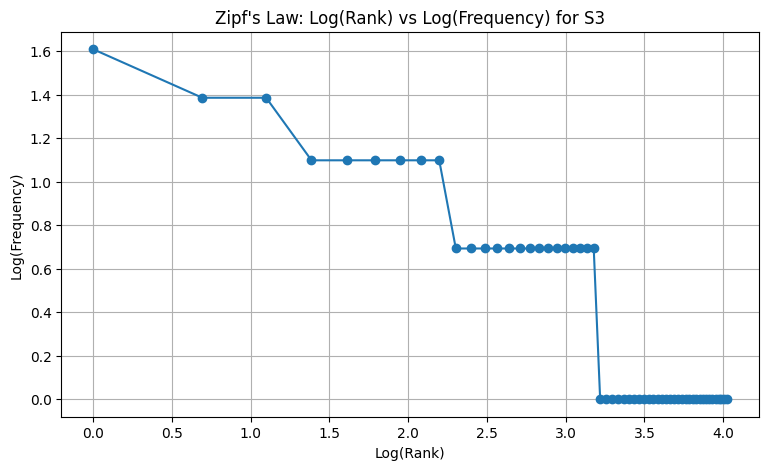


TOP 5 BIGRAMS IN S1
('.', 'i') : 8
('yesterday', '.') : 4
('.', 'the') : 4
('i', 'do') : 3
('do', "n't") : 3

TOP 5 BIGRAMS IN S3
("n't", 'know') : 3
('know', 'changed') : 3
('since', 'yesterday') : 3
('keeps', 'asking') : 2
('asking', 'login') : 2


In [ ]:
from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer
import matplotlib.pyplot as plt
import math

S1 = [token for result in results for token in result["tokens"]]

S2 = [token for result in results for token in result["tokens"]
      if not is_punct(token)]
S3 = [token for result in results for token in result["final"]]

porter = PorterStemmer()
S4 = [porter.stem(token) for token in S3]

def corpus_stats(tokens):
    total_tokens = len(tokens)
    unique_tokens = len(set(tokens))
    ttr = unique_tokens / total_tokens if total_tokens else 0

    return {
        "Total Tokens": total_tokens,
        "Unique Tokens": unique_tokens,
        "TTR": round(ttr, 4)
    }


statistics = pd.DataFrame({
    "S1 - All Tokens": corpus_stats(S1),
    "S2 - No Punctuation": corpus_stats(S2),
    "S3 - Final Tokens": corpus_stats(S3),
    "S4 - Porter Stemmed": corpus_stats(S4)
}).T

print("CORPUS STATISTICS")
display(statistics)

print("\nTOP 10 WORDS IN S1")

s1_frequency = Counter(S1)

for word, frequency in s1_frequency.most_common(10):
    print(f"{word}: {frequency}")


print("\nTOP 10 WORDS IN S3")

s3_frequency = Counter(S3)

for word, frequency in s3_frequency.most_common(10):
    print(f"{word}: {frequency}")

frequencies = sorted(s3_frequency.values(), reverse=True)

ranks = list(range(1, len(frequencies) + 1))

log_ranks = [math.log(rank) for rank in ranks]
log_frequencies = [math.log(freq) for freq in frequencies]

plt.figure(figsize=(9, 5))

plt.plot(log_ranks, log_frequencies, marker="o")

plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.title("Zipf's Law: Log(Rank) vs Log(Frequency) for S3")

plt.grid(True)
plt.show()

s1_bigrams = Counter(bigrams(S1))

print("\nTOP 5 BIGRAMS IN S1")

for bigram, frequency in s1_bigrams.most_common(5):
    print(bigram, ":", frequency)

s3_bigrams = Counter(bigrams(S3))

print("\nTOP 5 BIGRAMS IN S3")

for bigram, frequency in s3_bigrams.most_common(5):
    print(bigram, ":", frequency)

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*  TTR changes from S1 to S4 because each preprocessing stage modifies the corpus.
- S1: Contains all words, punctuation and stopwords, resulting in a large vocabulary.
- S2: Removing punctuation reduces the total number of tokens.
- S3: Removing stopwords further reduces the number of tokens and may change the proportion of unique words.
- S4: Porter stemming combines different word forms into common stems, reducing the number of unique tokens.
Therefore, stemming generally reduces vocabulary size and often decreases TTR. However, TTR does not necessarily decrease at every stage because both the numerator and denominator change during preprocessing.